# pyChartist quick start

One function per chart type; every call returns a `Chart` that displays inline, saves to PNG/SVG/PDF/HTML and drops into Dash. Pick the renderer with `backend=`.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import pandas as pd
import pychartist as pc
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"   # renders in JupyterLab/VS Code/Colab; plotly.js from CDN

## Data
All example data are freely available and downloaded once into `datasets/`.

In [2]:
pc.datasets.info()[['name', 'description', 'licence', 'downloaded']]

,name,description,licence,downloaded
0,penguins,Palmer penguins: bill/flipper/mass for 3 speci...,CC0,True
1,tips,Restaurant bills and tips by day/time/sex/smoker,public example data,True
2,titanic,"Titanic passengers: class, sex, age, survival",public domain,True
3,flights,Monthly airline passengers 1949-1960 (Box & Je...,public domain,True
4,mpg,"Auto MPG: fuel economy, horsepower, weight, or...",CC BY 4.0,True
5,iris,Fisher's iris measurements,public domain,True
6,healthexp,"Health spending per capita vs life expectancy,...",OECD terms (free reuse),True
7,gapminder,"Gapminder: population, life expectancy, GDP pe...",CC BY 4.0,True
8,apple_stock,AAPL daily OHLC prices 2015-2017,public example data,True
9,world_gdp,GDP (billions USD) by country with ISO-3 codes...,public domain,True


In [3]:
pen = pc.datasets.load('penguins')
pen.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## The same chart, three backends
`matplotlib` (static, publication), `seaborn` (static, with statistical estimation - here 95% bootstrap CI error bars) and `plotly` (interactive).

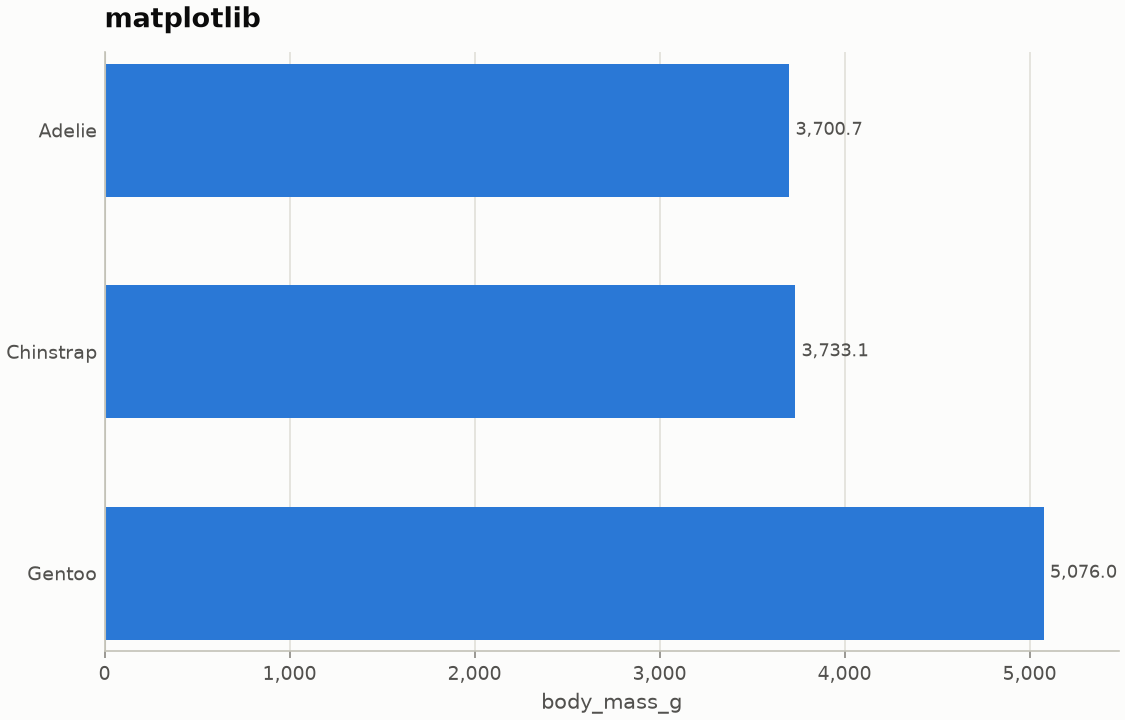

In [4]:
pc.bar(pen, 'species', 'body_mass_g', agg='mean', title='matplotlib')

{'error_bars': '95% bootstrap confidence interval of the mean'}


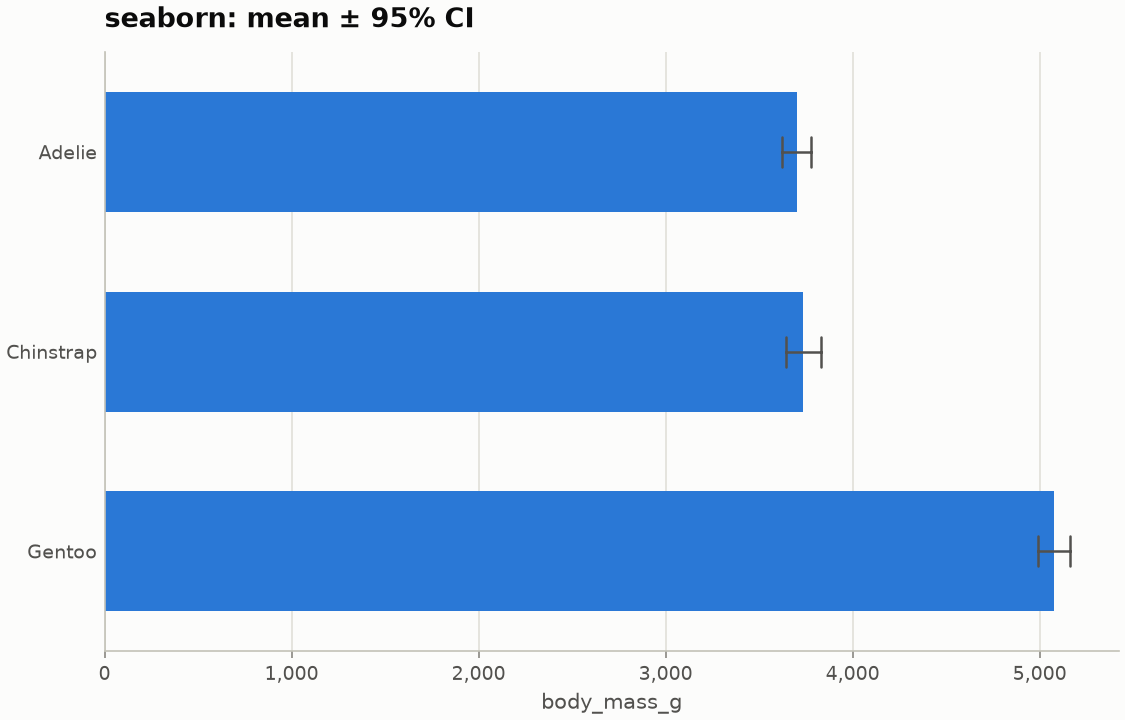

In [5]:
c = pc.bar(pen, 'species', 'body_mass_g', agg='mean', backend='seaborn', title='seaborn: mean ± 95% CI')
print(c.meta)
c

In [6]:
pc.bar(pen, 'species', 'body_mass_g', agg='mean', backend='plotly', title='plotly: hover me')

<Chart kind='bar' backend='plotly' theme='pychartist'>

## Set defaults once

In [7]:
pc.set_backend('plotly')
pc.violin(pen, 'species', 'flipper_length_mm', title='Default backend is now Plotly')

<Chart kind='violin' backend='plotly' theme='pychartist'>

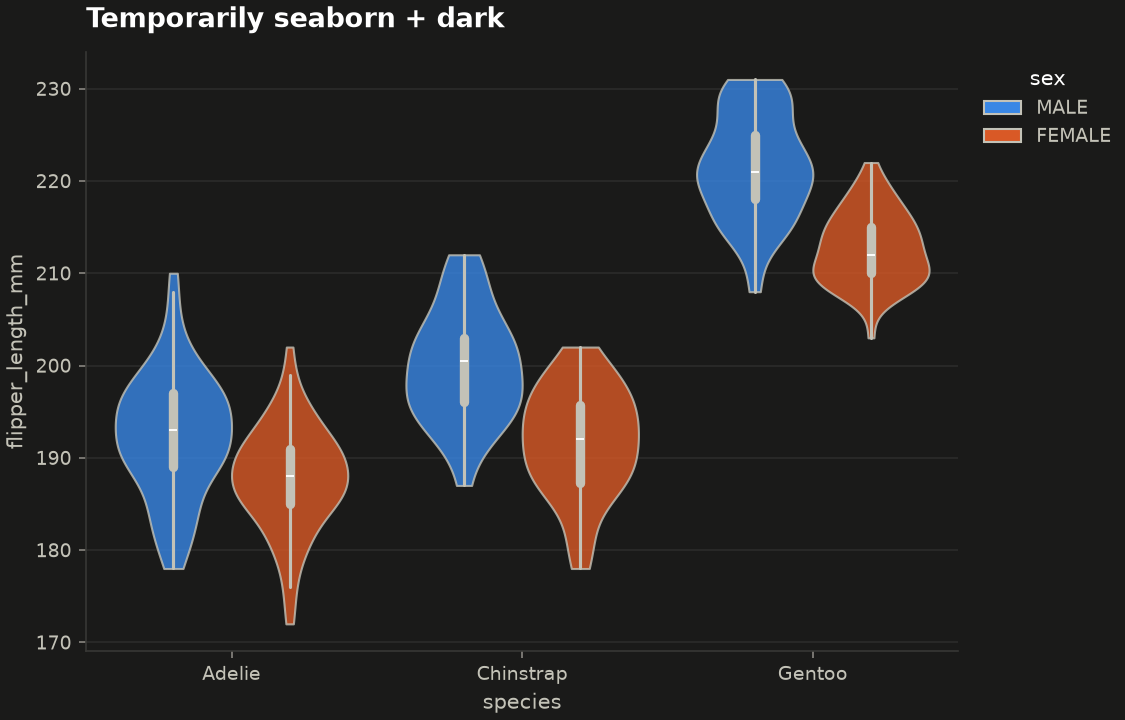

In [8]:
pc.set_backend('matplotlib')
with pc.options(backend='seaborn', theme='dark'):
    c = pc.violin(pen, 'species', 'flipper_length_mm', 'sex', title='Temporarily seaborn + dark')
c

## Saving and exporting

In [9]:
from pathlib import Path
out = Path('_output'); out.mkdir(exist_ok=True)
c = pc.scatter(pen, 'bill_length_mm', 'bill_depth_mm', 'species', trendline='ols')
for ext in ['png', 'svg', 'pdf', 'html']:
    print(c.save(out / f'scatter.{ext}'))
p = pc.scatter(pen, 'bill_length_mm', 'bill_depth_mm', 'species', backend='plotly')
print(p.save(out / 'scatter_interactive.html'), p.save(out / 'scatter_plotly.png', width=900, height=550))

_output/scatter.png
_output/scatter.svg


_output/scatter.pdf
_output/scatter.html


_output/scatter_interactive.html _output/scatter_plotly.png


## Composing with matplotlib
Pass `ax=` to draw into your own figure (matplotlib/seaborn backends).

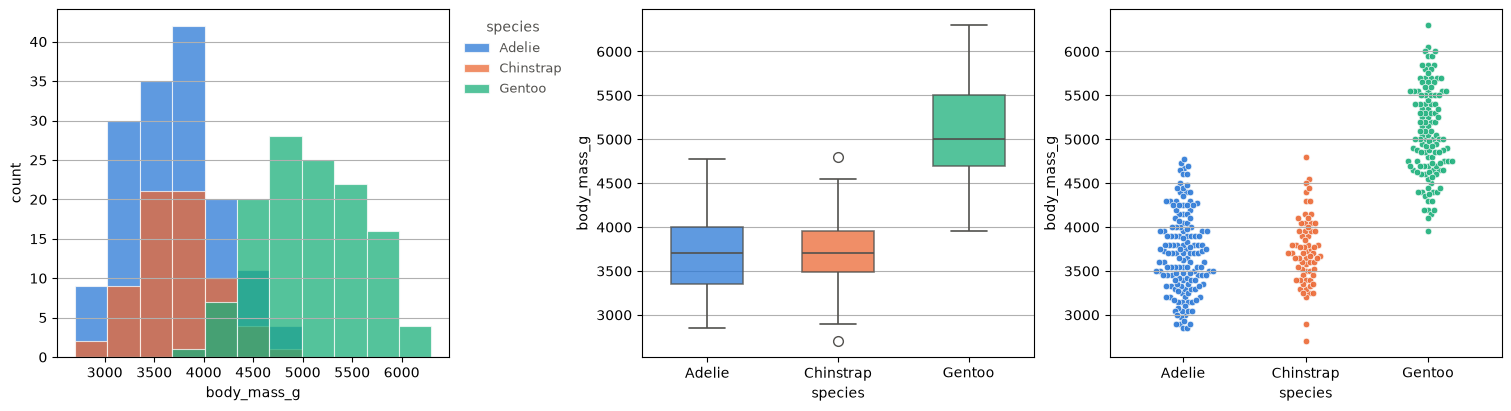

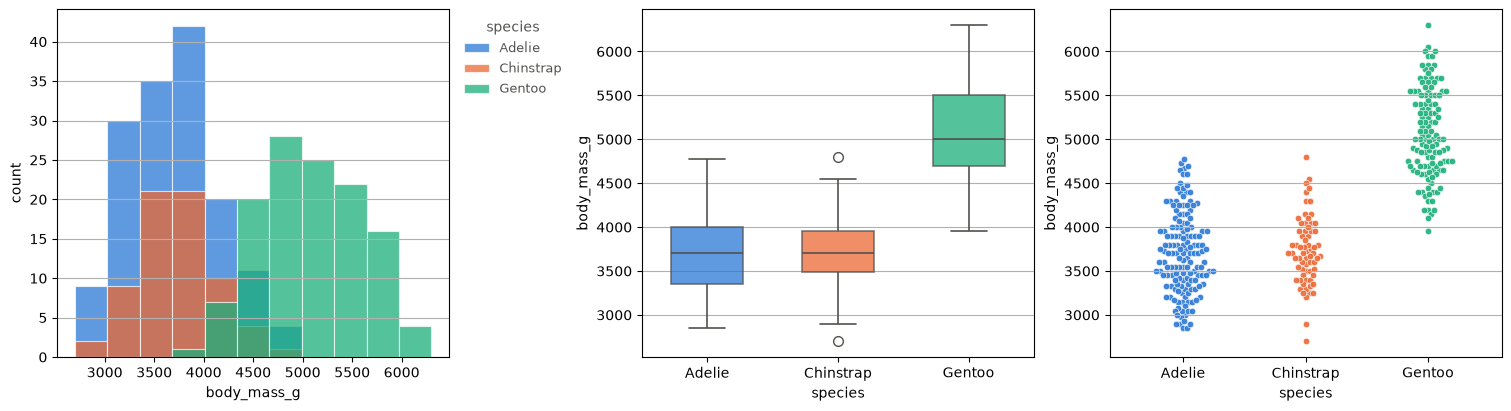

In [10]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
pc.histogram(pen, 'body_mass_g', 'species', ax=axes[0])
pc.box(pen, 'species', 'body_mass_g', ax=axes[1], backend='seaborn')
pc.beeswarm(pen, 'species', 'body_mass_g', ax=axes[2])
fig

## The catalogue
Every chart from the reference list (77) plus five EDA extras, with alternative names and guidance on when (not) to use it. `pc.plot()` accepts any name or alias.

In [11]:
cat = pc.catalog()
print(len(cat), 'charts')
cat.groupby('category').size()

82 charts


category
1. Comparison                       22
2. Correlation (relational)          6
3. Part-to-whole & hierarchical     19
4. Data over time (temporal)        12
5. Distribution                     12
6. Geospatial & other                8
EDA (charts + statistical tests)     3
dtype: int64

In [12]:
cat[['chart', 'function', 'backends', 'alt_names']].head(12)

,chart,function,backends,alt_names
0,bar,pc.bar,"matplotlib, seaborn, plotly","bar chart, bar graph, horizontal bar chart"
1,column,pc.column,"matplotlib, seaborn, plotly","column graph, vertical bar chart, column chart"
2,grouped_bar,pc.grouped_bar,"matplotlib, seaborn, plotly","grouped bar chart, grouped column chart, clust..."
3,lollipop,pc.lollipop,"matplotlib, plotly","lollipop plot, lollipop chart"
4,bullet,pc.bullet,"matplotlib, plotly","bullet graph, bullet chart"
5,dot_plot,pc.dot_plot,"matplotlib, plotly","dot chart, cleveland dot plot, dot plot"
6,dumbbell,pc.dumbbell,"matplotlib, plotly","dumbbell plot, dumbbell chart, connected dot p..."
7,pictogram,pc.pictogram,"matplotlib, plotly","pictogram chart, pictorial chart, proportional..."
8,icon_chart,pc.icon_chart,"matplotlib, plotly","proportional area chart, icon chart"
9,range_plot,pc.range_plot,"matplotlib, plotly","range chart, range bar chart, floating bar chart"


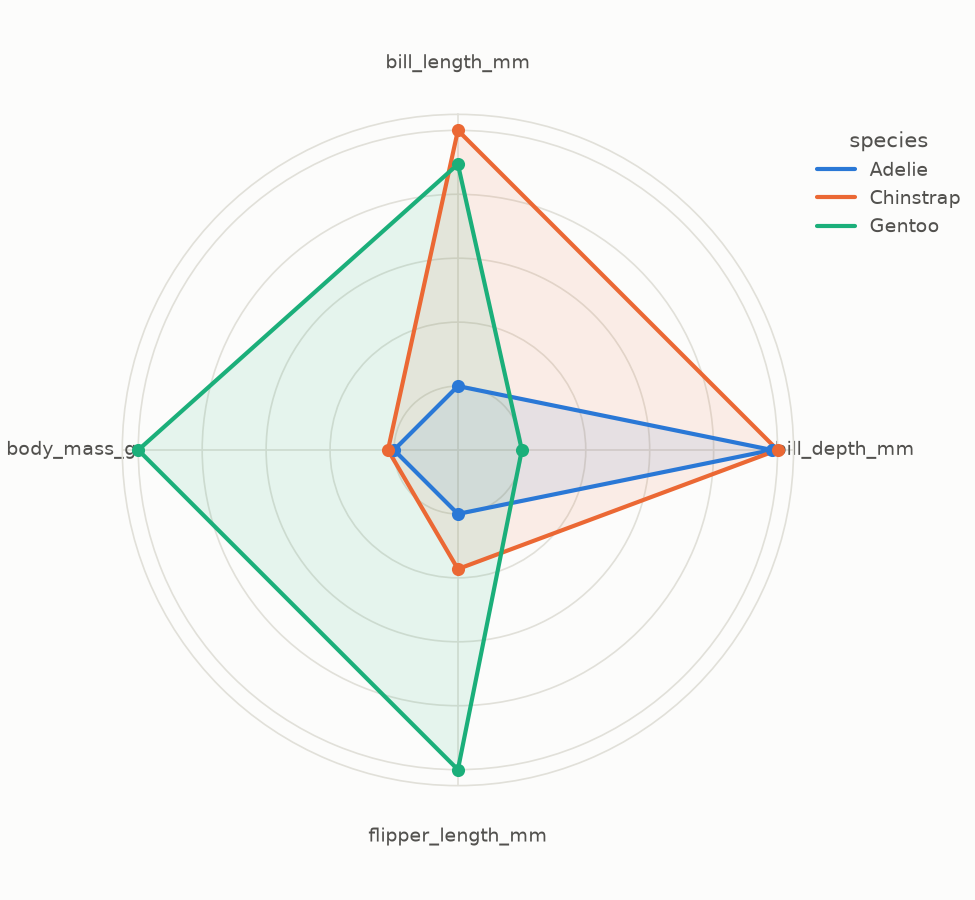

In [13]:
pc.plot('spider chart', pen, 'species', ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g'])

## Every chart has a ready-made demo

In [14]:
pc.examples.demo('sankey', backend='plotly')

<Chart kind='sankey' backend='plotly' theme='pychartist'>